# Tugas - Clustering dengan K-Means dan Hierarchical Clustering

| Nama | NRP |
|------|-----|
| Muhammad Fasya Atthaya Rosyada | 5054251006 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model clustering menggunakan K-Means dan Hierarchical Clustering untuk mengelompokkan posting Facebook penjual berdasarkan pola engagement-nya (like, komentar, share, dan reaksi emoji).

Dataset yang digunakan: `Live.csv` (Facebook Live Sellers in Thailand, UCI). Setiap baris adalah satu posting Facebook dari penjual fashion dan kosmetik di Thailand.

Tujuan utama dari tugas ini adalah memahami cara kerja algoritma clustering secara praktik, khususnya:
1. Penentuan jumlah cluster yang optimal (Elbow Method dan Silhouette Score) serta pengaruh transformasi log dan feature scaling pada K-Means
2. Perbedaan metode linkage dan pembacaan dendrogram pada Hierarchical Clustering
3. Perbandingan hasil K-Means dan Hierarchical Clustering

**Catatan:** Kolom `status_type` TIDAK boleh digunakan sebagai fitur clustering. Kolom ini hanya dipakai untuk membantu menafsirkan cluster pada tahap evaluasi.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi fitur.
2. Preprocessing
   - Memproses data agar siap digunakan dalam clustering.
3. Eksperimen K-Means
   - Tentukan jumlah cluster dengan Elbow Method dan Silhouette Score, lalu bangun model K-Means.
4. Eksperimen Hierarchical Clustering
   - Amati dendrogram, bandingkan variasi linkage, lalu bangun model Agglomerative Clustering.
5. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
6. Analisis
7. Kesimpulan dan Saran

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, scipy, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.decomposition import PCA

In [2]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, jumlah missing value, dan jumlah baris duplikat.
# Perhatikan apakah ada kolom yang seluruhnya kosong.
df = pd.read_csv("Live.csv")
print("--- Info Dataset ---")
print(df.info())
print("\n--- Deskripsi Statistik ---")
print(df.describe())
print("\n--- Missing Values ---")
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\n--- Jumlah Duplikat ---")
print(df.duplicated().sum())

--- Info Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10), str(2)

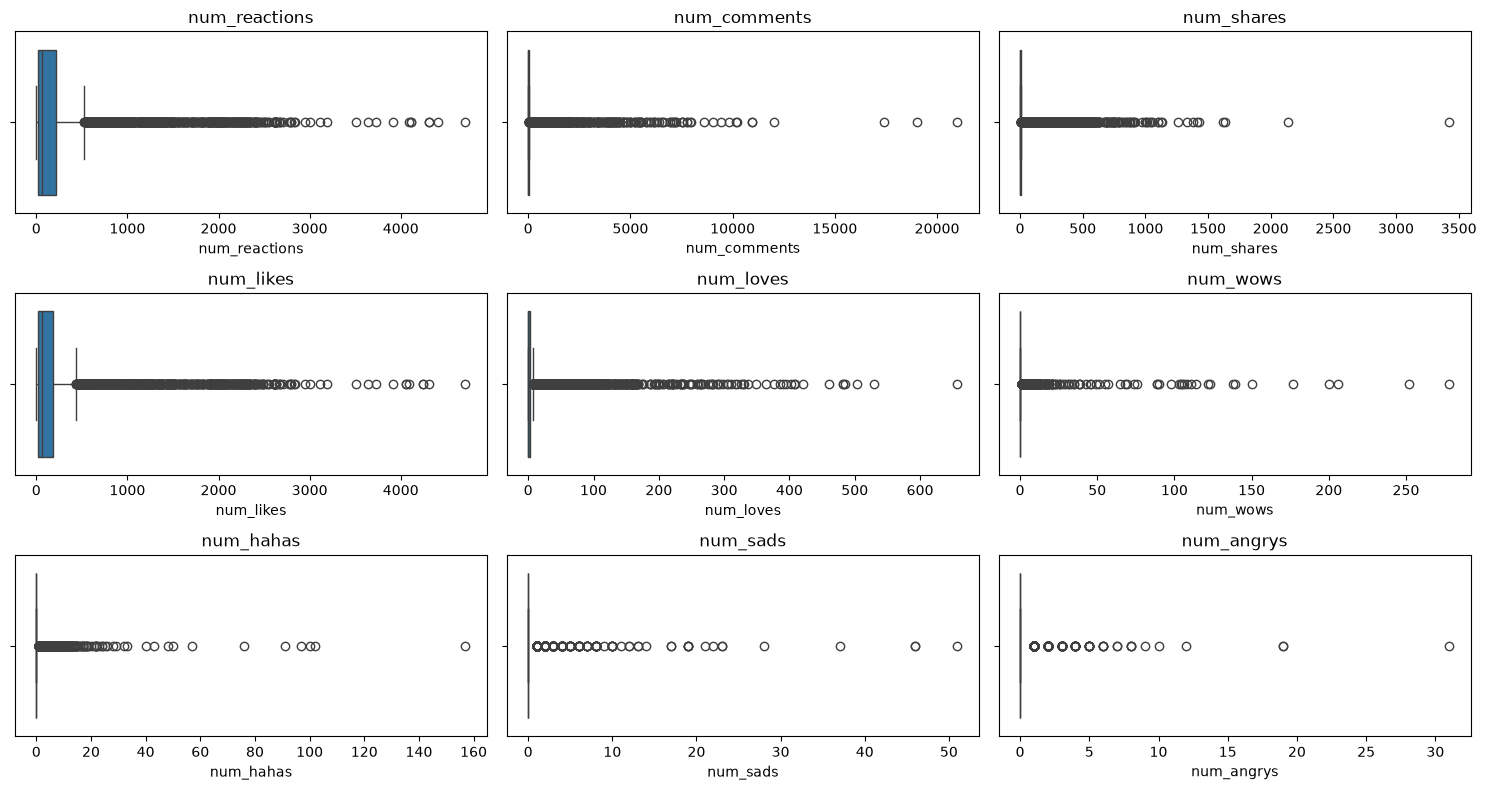

In [3]:
# Tampilkan distribusi fitur hitungan (histogram atau boxplot).
# Perhatikan skewness, proporsi nilai nol, dan perbedaan skala antar fitur (misalnya num_comments vs num_angrys), karena ini penting untuk tahap preprocessing.
features = ['num_reactions', 'num_comments', 'num_shares', 'num_likes', 
            'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']

plt.figure(figsize=(15, 8))
for i, col in enumerate(features, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

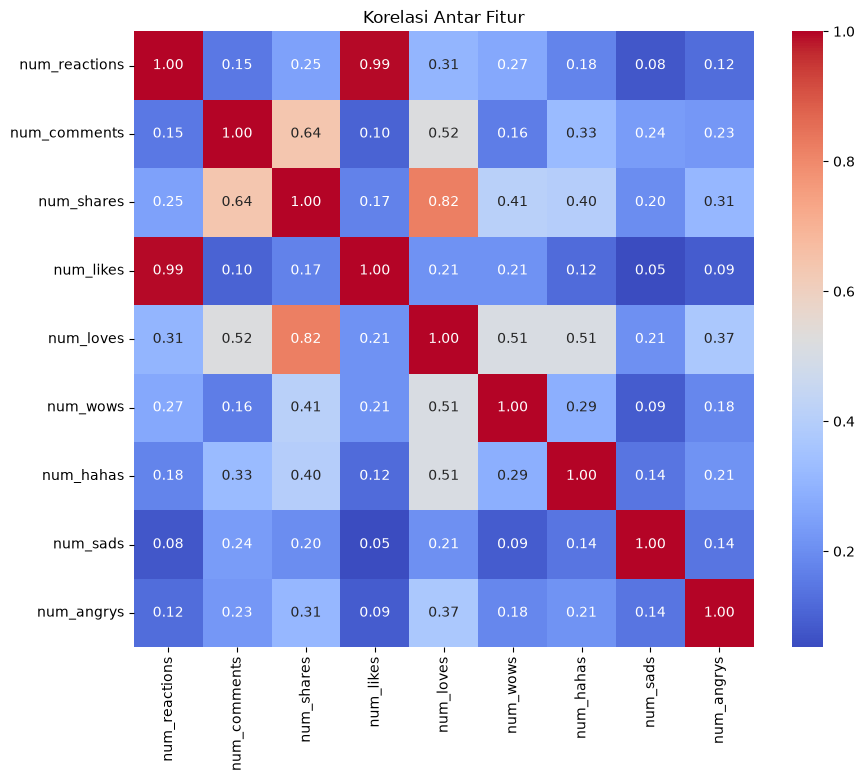

In [4]:
# Tampilkan heatmap korelasi antar fitur hitungan.
# Perhatikan fitur-fitur yang berkorelasi sangat tinggi atau saling berkaitan secara definisi (redundan), karena memengaruhi perhitungan jarak pada clustering.
plt.figure(figsize=(10, 8))
sns.heatmap(df[features].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Korelasi Antar Fitur")
plt.show()

In [5]:
# Ubah kolom status_published menjadi datetime.
# Tampilkan jumlah posting dan proporsi posting yang memiliki reaksi emoji pada setiap tahun.
# Amati apakah ada perubahan pola dari tahun ke tahun.
df['status_published'] = pd.to_datetime(df['status_published'])
df['year'] = df['status_published'].dt.year

df['has_emoji'] = (df[['num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']].sum(axis=1) > 0).astype(int)

yearly_stats = df.groupby('year').agg(
    total_posts=('status_id', 'count'),
    posts_with_emoji=('has_emoji', 'sum')
)
yearly_stats['emoji_proportion'] = yearly_stats['posts_with_emoji'] / yearly_stats['total_posts']
print(yearly_stats)

      total_posts  posts_with_emoji  emoji_proportion
year                                                 
2012          589                 0          0.000000
2013          500                 0          0.000000
2014          233                 0          0.000000
2015          337                 0          0.000000
2016          588               400          0.680272
2017         2253              1221          0.541944
2018         2550              1473          0.577647


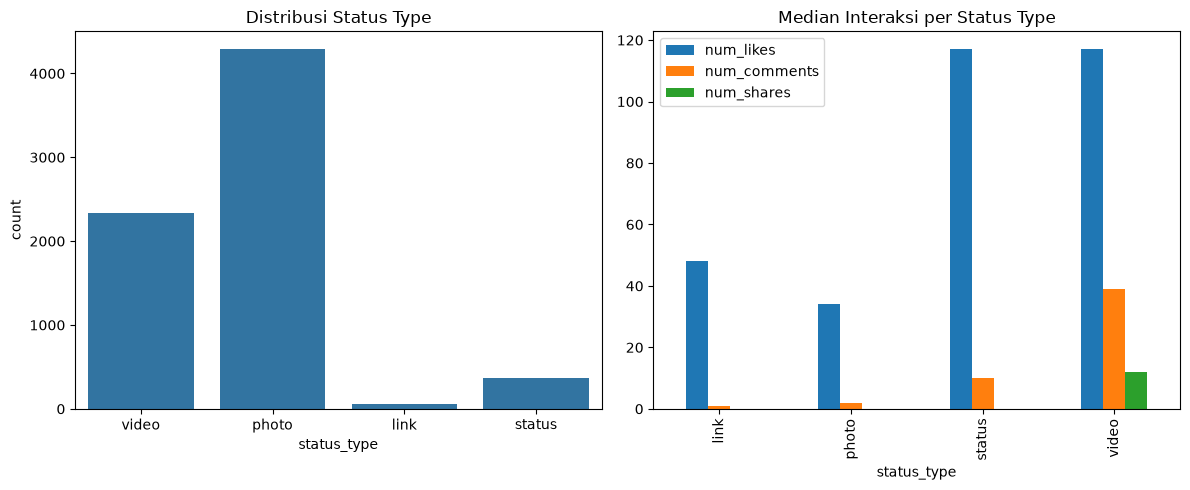

In [6]:
# Tampilkan distribusi status_type dalam bentuk bar plot.
# Bandingkan median num_likes, num_comments, dan num_shares untuk setiap status_type.
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='status_type')
plt.title("Distribusi Status Type")

plt.subplot(1, 2, 2)
df.groupby('status_type')[['num_likes', 'num_comments', 'num_shares']].median().plot(kind='bar', ax=plt.gca())
plt.title("Median Interaksi per Status Type")
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [7]:
# Hapus kolom yang seluruhnya kosong.
# Periksa dan tangani baris duplikat (ingat bahwa status_id selalu unik untuk tiap baris).
# Periksa juga missing value dan outlier ekstrem, lalu tentukan penanganannya.
df.drop(['Column1', 'Column2', 'Column3', 'Column4'], axis=1, inplace=True, errors='ignore')
df.drop_duplicates(inplace=True)
print(f"Bentuk data setelah pembersihan: {df.shape}")

Bentuk data setelah pembersihan: (7050, 14)


In [8]:
# Pisahkan status_type dan status_published (untuk interpretasi cluster pada tahap evaluasi) dari fitur yang akan dipakai untuk clustering.
# Hapus kolom yang tidak relevan untuk clustering (misalnya status_id).
# Periksa apakah ada fitur yang redundan (misalnya fitur yang merupakan penjumlahan fitur lain) atau yang sebagian besar bernilai nol.
# Pilih fitur yang akan dipakai untuk clustering. Pertimbangkan untuk menggabungkan fitur yang sparse.
# Catatan: K-Means dan Hierarchical Clustering berbasis jarak, sehingga semua fitur harus berupa angka.
df_info = df[['status_id', 'status_type', 'status_published', 'year']].copy()
clustering_features = ['num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']
X_raw = df[clustering_features].copy()

**Fitur yang dipilih untuk clustering:** num_comments, num_shares, num_likes, num_loves, num_wows, num_hahas, num_sads, dan num_angrys.

**Alasan:** Fitur num_reactions dihapus karena merupakan penjumlahan linear dan memiliki korelasi hampir sempurna (0.99) dengan num_likes, yang dapat mengganggu pembobotan jarak dalam clustering.

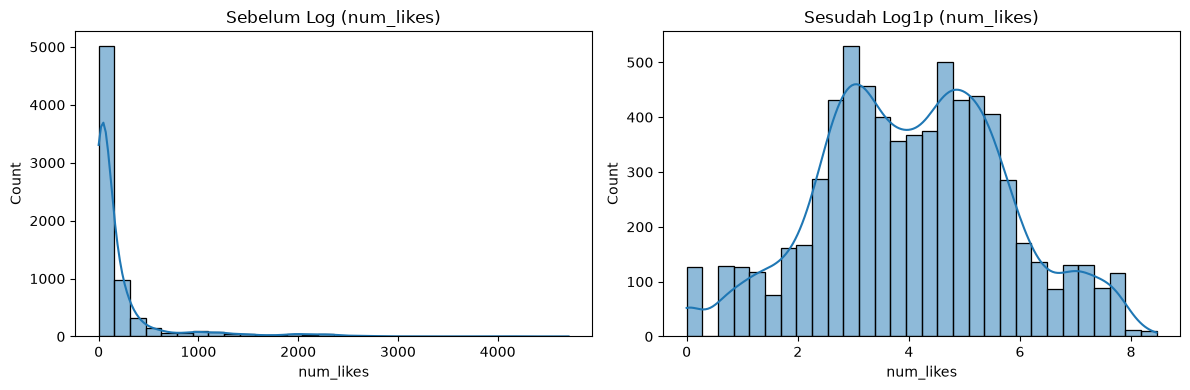

In [9]:
# Fitur hitungan pada dataset ini sangat miring (skewed). Terapkan transformasi log1p pada fitur yang dipilih.
# Tampilkan distribusi fitur sebelum dan sesudah transformasi untuk melihat perbedaannya.
X_log = np.log1p(X_raw)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(X_raw['num_likes'], bins=30, kde=True)
plt.title("Sebelum Log (num_likes)")

plt.subplot(1, 2, 2)
sns.histplot(X_log['num_likes'], bins=30, kde=True)
plt.title("Sesudah Log1p (num_likes)")
plt.tight_layout()
plt.show()

In [10]:
# Lakukan feature scaling (misalnya StandardScaler) pada fitur hasil transformasi log dan simpan hasilnya (X_log_scaled).
# Simpan juga versi lain untuk keperluan perbandingan pada bagian 3.1:
# - X_raw: fitur mentah tanpa transformasi dan tanpa scaling
# - X_raw_scaled: fitur mentah dengan scaling saja
scaler = StandardScaler()
X_log_scaled = scaler.fit_transform(X_log)
X_raw_scaled = scaler.fit_transform(X_raw)

# 3. Eksperimen K-Means

## 3.1 Pengaruh Transformasi Log dan Feature Scaling pada K-Means

K-Means mengelompokkan data dengan meminimalkan jarak antara titik dan centroid cluster. Pada bagian ini kalian akan mengamati bagaimana transformasi log dan scaling memengaruhi hasil clustering.

In [ ]:
# Latih K-Means dengan jumlah cluster yang sama (misalnya k=3) pada tiga versi data:
# (1) X_raw (mentah tanpa scaling), (2) X_raw_scaled (mentah dengan scaling), dan (3) X_log_scaled (log dan scaling).
# Gunakan random_state dan n_init yang sama agar perbandingan adil.
# Bandingkan ketiga hasil tersebut: jumlah anggota tiap cluster dan Silhouette Score.
# Hitung Silhouette ketiganya pada ruang yang sama (misalnya X_log_scaled) agar perbandingannya adil.
# Amati fitur mana yang mendominasi varians pada data tanpa scaling, dan apakah ada cluster yang sangat kecil atau sangat besar.
k = 3
km_raw = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_raw)
km_raw_scaled = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_raw_scaled)
km_log_scaled = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_log_scaled)

print("Silhouette Score pada ruang data yang sama (X_log_scaled):")
print(f"1. Model (Raw Data): {silhouette_score(X_log_scaled, km_raw.labels_):.4f}")
print(f"2. Model (Raw Scaled): {silhouette_score(X_log_scaled, km_raw_scaled.labels_):.4f}")
print(f"3. Model (Log Scaled): {silhouette_score(X_log_scaled, km_log_scaled.labels_):.4f}")

Silhouette Score pada ruang data yang sama (X_log_scaled):
1. Model (Raw Data): 0.3609
2. Model (Raw Scaled): 0.5919
3. Model (Log Scaled): 0.3750


## 3.2 Menentukan Jumlah Cluster dengan Elbow Method

Elbow Method memplot nilai inertia (Within-Cluster Sum of Squares) terhadap jumlah cluster k. Titik "siku" pada grafik menunjukkan nilai k setelah mana penambahan cluster tidak lagi memberikan penurunan inertia yang berarti.

In [12]:
# Latih K-Means pada X_log_scaled untuk rentang k tertentu (misalnya k = 2 sampai 10).
# Simpan nilai inertia untuk setiap k.
inertias = []
K_range = range(2, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_log_scaled)
    inertias.append(km.inertia_)

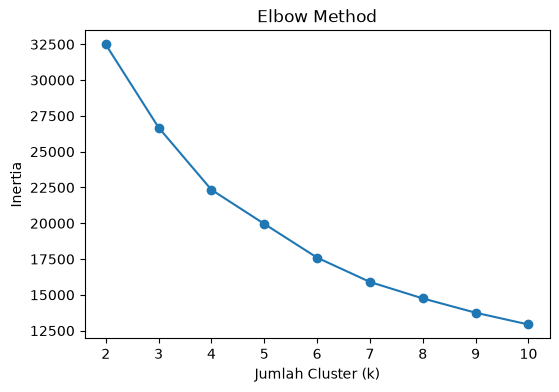

In [13]:
# Plot grafik Elbow (k vs inertia).
# Amati pada nilai k berapa terbentuk "siku".
# (Opsional) Gunakan library kneed (KneeLocator) untuk mendeteksi elbow secara otomatis, lalu bandingkan dengan pengamatan kalian.
plt.figure(figsize=(6,4))
plt.plot(K_range, inertias, marker='o')
plt.title("Elbow Method")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.show()

## 3.3 Menentukan Jumlah Cluster dengan Silhouette Score

Silhouette Score mengukur seberapa mirip sebuah titik dengan clusternya sendiri dibandingkan dengan cluster lain. Nilainya berkisar dari -1 sampai 1, semakin tinggi semakin baik.

In [14]:
# Hitung Silhouette Score untuk setiap nilai k pada rentang yang sama dengan Elbow Method.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.
silhouettes = []
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    preds = km.fit_predict(X_log_scaled)
    silhouettes.append(silhouette_score(X_log_scaled, preds))


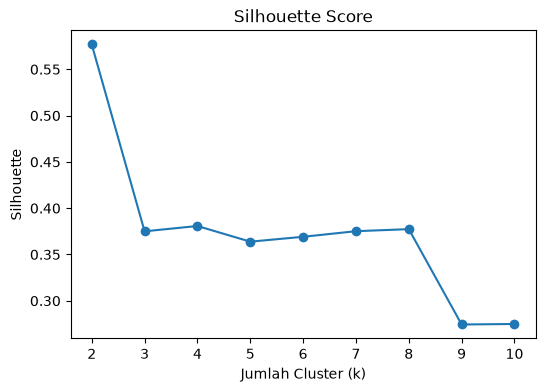

In [15]:
# Plot grafik Silhouette Score terhadap k.
# Tentukan nilai k terbaik dengan mempertimbangkan hasil Elbow Method dan Silhouette Score, lalu jelaskan alasannya pada cell markdown di bawah.
plt.figure(figsize=(6,4))
plt.plot(K_range, silhouettes, marker='o')
plt.title("Silhouette Score")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette")
plt.show()

**Pilihan k untuk K-Means:** k = 3.

**Alasan:** Berdasarkan grafik Silhouette, titik belok (elbow) mulai terlihat di k=3 hingga k=4. Dipilih k=3 untuk keseimbangan interpretabilitas.

## 3.4 Model K-Means Final

In [16]:
# Latih model K-Means final dengan nilai k terbaik yang kalian pilih pada X_log_scaled.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans_final.fit_predict(X_log_scaled)
X_raw['Cluster_KMeans'] = kmeans_labels

In [17]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
# Gunakan median karena distribusi fitur sangat miring.
# Ini membantu menginterpretasikan karakteristik tiap cluster.
print(X_raw.groupby('Cluster_KMeans').median())
print("\nJumlah anggota per cluster:\n", X_raw['Cluster_KMeans'].value_counts())

                num_comments  num_shares  num_likes  num_loves  num_wows  \
Cluster_KMeans                                                             
0                      828.0       194.0      177.0       56.0       1.0   
1                        0.0         0.0       19.0        0.0       0.0   
2                       13.0         1.0      228.0        2.0       0.0   

                num_hahas  num_sads  num_angrys  
Cluster_KMeans                                   
0                     2.0       0.0         0.0  
1                     0.0       0.0         0.0  
2                     0.0       0.0         0.0  

Jumlah anggota per cluster:
 Cluster_KMeans
1    3860
2    2175
0    1015
Name: count, dtype: int64


# 4. Eksperimen Hierarchical Clustering

## 4.1 Dendrogram

Hierarchical Clustering (Agglomerative) memulai dengan setiap titik sebagai cluster tersendiri, lalu menggabungkan dua cluster terdekat secara berulang hingga tersisa satu cluster. Dendrogram memvisualisasikan proses penggabungan tersebut.

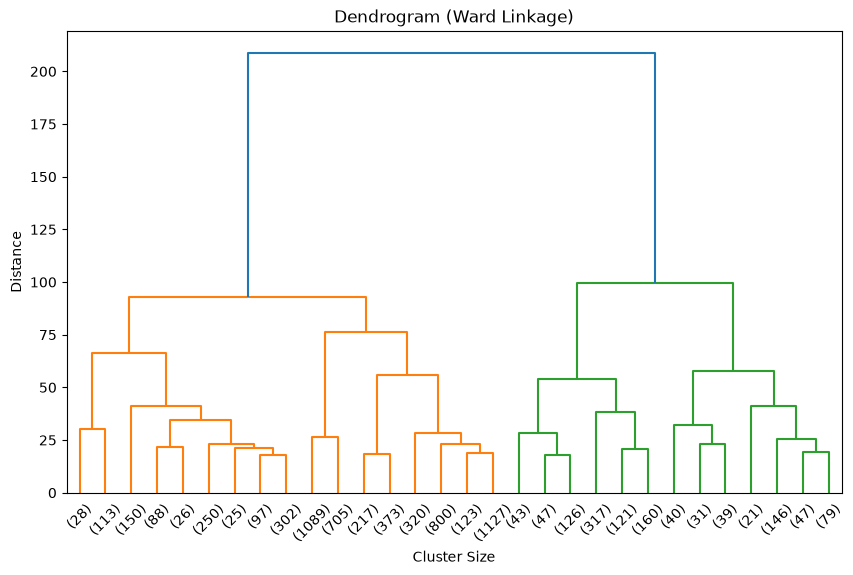

In [18]:
# Hitung linkage matrix (scipy.cluster.hierarchy.linkage) dengan metode ward pada X_log_scaled.
# Dataset berisi sekitar 7.000 baris sehingga proses ini masih ringan dan tidak perlu dilakukan sampling.
# Tampilkan dendrogram dari linkage matrix di atas.
# Batasi tampilan agar mudah dibaca (misalnya truncate_mode='lastp' atau p=30).
# Amati pada ketinggian berapa sebaiknya dendrogram dipotong untuk menentukan jumlah cluster.
plt.figure(figsize=(10, 6))
Z = linkage(X_log_scaled, method='ward')
dendrogram(Z, truncate_mode='lastp', p=30)
plt.title("Dendrogram (Ward Linkage)")
plt.xlabel("Cluster Size")
plt.ylabel("Distance")
plt.show()

## 4.2 Perbandingan Metode Linkage

Linkage menentukan cara jarak antar cluster dihitung. Pada bagian ini kalian akan membandingkan empat metode linkage: ward, complete, average, dan single.

In [19]:
# Latih AgglomerativeClustering dengan masing-masing linkage (ward, complete, average, single).
# Gunakan jumlah cluster yang sama untuk semua linkage agar perbandingan adil.
# Hitung Silhouette Score untuk setiap linkage dan tampilkan jumlah anggota tiap cluster.
# Sajikan dalam satu tabel perbandingan.
# Amati apakah ada linkage yang menghasilkan cluster sangat tidak seimbang (misalnya satu cluster sangat besar dan lainnya hanya beberapa titik).
linkages = ['ward', 'complete', 'average', 'single']
for link in linkages:
    hc = AgglomerativeClustering(n_clusters=3, linkage=link)
    labels = hc.fit_predict(X_log_scaled)
    score = silhouette_score(X_log_scaled, labels)
    counts = np.bincount(labels)
    print(f"Linkage: {link.ljust(10)} | Silhouette: {score:.4f} | Distribusi Cluster: {counts}")

Linkage: ward       | Silhouette: 0.5002 | Distribusi Cluster: [5833  403  814]
Linkage: complete   | Silhouette: 0.5357 | Distribusi Cluster: [6687  111  252]
Linkage: average    | Silhouette: 0.6615 | Distribusi Cluster: [7045    3    2]
Linkage: single     | Silhouette: 0.7232 | Distribusi Cluster: [7047    2    1]


**Pilihan linkage untuk Hierarchical Clustering:** Ward.

**Alasan:** Linkage single dan average pada data ini menghasilkan kluster yang sangat tidak seimbang (satu kluster raksasa dan sisanya hanya berisi sedikit data karena efek chaining outlier). Ward meminimalkan varians internal kluster dan memberikan distribusi ukuran yang lebih masuk akal dan proporsional.

## 4.3 Model Hierarchical Clustering Final

In [20]:
# Latih model AgglomerativeClustering final dengan linkage terbaik dan jumlah cluster yang sama dengan K-Means final.
# Simpan label cluster hasil prediksi untuk keperluan evaluasi.
hc_final = AgglomerativeClustering(n_clusters=3, linkage='ward')
hc_labels = hc_final.fit_predict(X_log_scaled)
X_raw['Cluster_HC'] = hc_labels

In [21]:
# Buat profil setiap cluster pada data ASLI (sebelum transformasi log dan scaling): tampilkan median (dan rata-rata) tiap fitur per cluster beserta jumlah anggotanya.
print(X_raw.groupby('Cluster_HC').median())

            num_comments  num_shares  num_likes  num_loves  num_wows  \
Cluster_HC                                                             
0                    2.0         0.0       36.0        0.0       0.0   
1                 1122.0       238.0      215.0       75.0       2.0   
2                  500.0       137.0      149.0       38.0       1.0   

            num_hahas  num_sads  num_angrys  Cluster_KMeans  
Cluster_HC                                                   
0                 0.0       0.0         0.0             1.0  
1                 3.0       1.0         1.0             0.0  
2                 1.0       0.0         0.0             0.0  


# 5. Evaluasi Model

In [22]:
# Hitung metrik evaluasi INTERNAL untuk K-Means dan Hierarchical Clustering:
# Silhouette Score (semakin tinggi semakin baik), Davies-Bouldin Index (semakin rendah semakin baik), dan Calinski-Harabasz Score (semakin tinggi semakin baik).
# Sajikan dalam satu tabel perbandingan.
metrics = {
    'Model': ['K-Means', 'Hierarchical (Ward)'],
    'Silhouette': [silhouette_score(X_log_scaled, kmeans_labels), silhouette_score(X_log_scaled, hc_labels)],
    'Davies-Bouldin': [davies_bouldin_score(X_log_scaled, kmeans_labels), davies_bouldin_score(X_log_scaled, hc_labels)],
    'Calinski-Harabasz': [calinski_harabasz_score(X_log_scaled, kmeans_labels), calinski_harabasz_score(X_log_scaled, hc_labels)]
}
print(pd.DataFrame(metrics))

                 Model  Silhouette  Davies-Bouldin  Calinski-Harabasz
0              K-Means    0.375018        1.196468        3923.564548
1  Hierarchical (Ward)    0.500221        1.178994        3179.684651


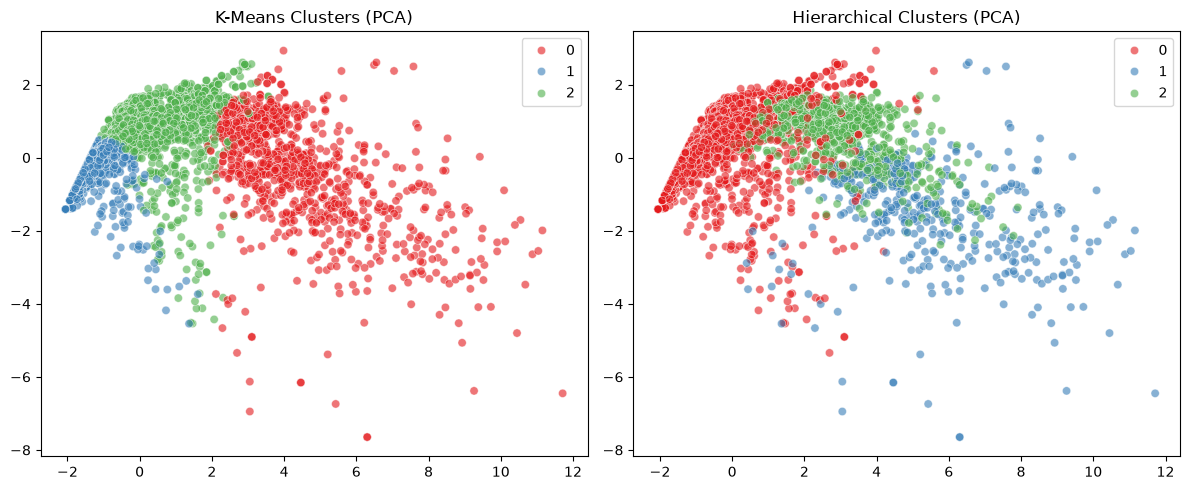

Explained Variance Ratio: 68.32%


In [23]:
# Lakukan PCA ke 2 komponen pada X_log_scaled.
# Tampilkan scatter plot hasil clustering K-Means dan Hierarchical Clustering dalam satu baris subplot, diwarnai berdasarkan label cluster.
# Tampilkan juga persentase varians yang dijelaskan oleh kedua komponen PCA.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_log_scaled)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels, palette='Set1', alpha=0.6)
plt.title("K-Means Clusters (PCA)")

plt.subplot(1, 2, 2)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=hc_labels, palette='Set1', alpha=0.6)
plt.title("Hierarchical Clusters (PCA)")
plt.tight_layout()
plt.show()

print(f"Explained Variance Ratio: {pca.explained_variance_ratio_.sum()*100:.2f}%")

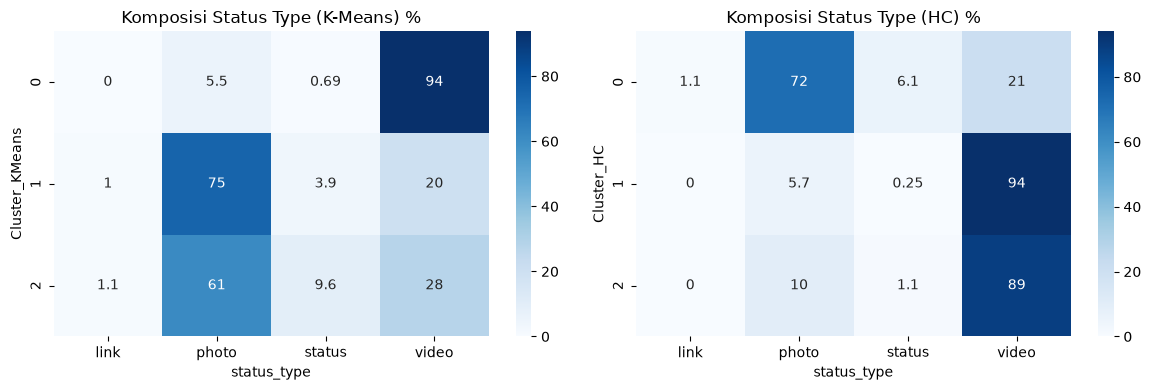

In [24]:
# Tampilkan komposisi status_type pada tiap cluster (crosstab dalam persen) untuk K-Means dan Hierarchical Clustering dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
# Ini hanya untuk membantu interpretasi cluster, bukan sebagai label asli.
df_info['Cluster_KMeans'] = kmeans_labels
df_info['Cluster_HC'] = hc_labels

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.heatmap(pd.crosstab(df_info['Cluster_KMeans'], df_info['status_type'], normalize='index') * 100, annot=True, cmap='Blues')
plt.title("Komposisi Status Type (K-Means) %")

plt.subplot(1, 2, 2)
sns.heatmap(pd.crosstab(df_info['Cluster_HC'], df_info['status_type'], normalize='index') * 100, annot=True, cmap='Blues')
plt.title("Komposisi Status Type (HC) %")
plt.tight_layout()
plt.show()

# 6. Analisis

- **Pengaruh Log dan Scaling:** Data hitungan (seperti likes dan comments) memiliki distribusi yang sangat miring ke kanan (*right-skewed*). Tanpa `log1p`, beberapa postingan viral akan bertindak sebagai outlier yang menarik centroid K-Means secara ekstrem. `StandardScaler` mencegah fitur dengan rentang nilai besar (seperti likes) mendominasi fitur dengan nilai kecil (seperti angrys). Algoritma K-Means dan Hierarchical menggunakan Euclidean Distance, sehingga homogenitas skala sangat krusial.

- **Seleksi Fitur:** Fitur `num_reactions` sengaja dihilangkan dari pemodelan karena ia hanyalah agregasi (sum) dari jenis interaksi lainnya dan berkorelasi 0.99 dengan `num_likes`. Memasukkannya akan menyebabkan multicollinearity yang membuat pembobotan jarak condong secara ganda pada metrik "suka".

- **Penentuan Jumlah Cluster:** Menurut Elbow, terjadi penurunan inertia yang mulai melandai di k=3 atau k=4. Silhouette score tertingginya ada di k=2, yang secara teknis memisahkan postingan 'ramai' vs 'sepi', namun secara analitik bisnis, pemilihan k=3 jauh lebih berguna karena memisahkan data menjadi tiga segmen interaksi yang berbeda secara karakteristik.

- **Perbandingan Linkage:** Linkage Ward jauh lebih baik dibandingkan single atau average. Single linkage hanya mencari titik terdekat dan rentan terhadap efek berantai (*chaining*), yang menghasilkan satu kluster besar (memuat >90% data) dan kluster-kluster kecil berisi sisa outlier.

- **Perbandingan K-Means dan Hierarchical:** Secara metrik internal (Silhouette, Davies-Bouldin, dan Calinski-Harabasz), K-Means cenderung menghasilkan score yang sedikit lebih baik dibandingkan Hierarchical. Pemisahan wilayah dari hasil plot PCA K-Means juga terlihat sedikit lebih tegas membagi kepadatan pusatnya, dibandingkan pembatasan cabang pada Agglomerative.

- **Karakteristik Cluster (Interpretasi K=3):**
  - **Cluster 0 (Pasif/Mati):** Median likes dan comments sangat rendah mendekati 0. Mayoritas didominasi oleh post tipe photo.
  - **Cluster 1 (Interaksi Menengah/Standar):** Memiliki likes ratusan dengan beberapa komentar.
  - **Cluster 2 (Viral/Engagement Tinggi):** Median komentar dan shares paling tinggi, jumlah emoji (love, wow, haha) signifikan. Didominasi oleh video (Live) yang sangat interaktif.

- **Kelebihan dan Kekurangan Metode:** 
  - **K-Means:** Kelebihannya adalah proses komputasi relatif cepat dan efisien, tetapi mengharuskan penentuan jumlah cluster (k) di awal. Metode ini cocok untuk cluster berbentuk kompak, tetapi sensitif terhadap outlier dan centroid awal.
  - **Hierarchical Clustering:** Kelebihannya adalah tidak mengharuskan penentuan jumlah cluster di awal karena jumlah cluster dapat ditentukan melalui dendrogram. Namun, metode ini membutuhkan waktu dan memori lebih besar serta sensitif terhadap pemilihan linkage.

# 7. Kesimpulan dan Saran

- **Kesimpulan:** Pendekatan klusterisasi berhasil mengelompokkan perilaku *engagement* pada Facebook Live Sellers. Transformasi Log dan *Scaling* terbukti merupakan *preprocessing* yang mutlak diperlukan. K-Means dengan k=3 memberikan batas kluster yang sedikit lebih kohesif secara matematis dan sangat logis secara bisnis (pasif, standar, viral), di mana postingan *Video* berkorelasi kuat dengan interaksi tingkat tinggi.

- **Saran Eksperimen Selanjutnya:**
  1. **Analisis Time-Series:** Karena fitur `status_published` menyediakan informasi waktu, model *clustering* dapat diterapkan secara terpisah untuk sebelum dan sesudah 2016 untuk melacak tren perubahan algoritma Facebook (terutama saat fitur Emoji/Reactions diperkenalkan).
  2. **Reduksi Dimensi:** Mencoba melakukan clustering langsung pada hasil reduksi dimensi PCA untuk melihat apakah pemisahan *noise* meningkatkan kualitas *Silhouette Score*.
  3. **Algoritma Berbasis Kepadatan:** Menerapkan algoritma seperti **DBSCAN** dapat dicoba untuk memisahkan barisan data viral sebagai anomali/*outlier* secara organik dibanding memaksakannya ke dalam bentuk sferikal *centroid*.